In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import torch.nn as nn
import torch
import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import random
import cv2
import matplotlib.pyplot as plt
import wandb
import sklearn
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# EDA

In [2]:
TEST_DATA_PATH = "data/test"
TRAIN_DATA_PATH = "data/train"
train_csv = pd.read_csv("data/train.csv")
test_csv = pd.read_csv("data/test.csv")


In [7]:
train_csv

,image_id,Cat,Dog,Moris,Motya,Biatrix
0,7e17a6e589f9c891857b32bbb3652d19b7d5a215,0,0,0,0,0
1,7ad97bd6c7ef98373f43f2bbd1e41b2bbff4687e,1,0,0,0,0
2,d29be872d012d8766c5942847d1d721788fd9511,0,1,0,0,0
3,bec7727bfc721629997d782ec020ee555990128f,0,1,0,0,0
4,58bb7362153d945f48721004bc8fb2ee73a855b0,0,1,0,0,0
...,...,...,...,...,...,...
12255,c23e0b3a78dc5576e6977800b342a6a280431fd9,0,1,0,0,0
12256,b743b27462e4f63967eb2f384779c5c450a979a3,0,0,0,0,0
12257,4a13ad53b343e9697a61ecad63e63595d9e2a095,0,1,0,0,0
12258,697cf9eb9a220684445c5dc88d8bafe8b24e3c95,0,1,0,0,0


In [38]:
biatrix_ids = train_csv[train_csv["Biatrix"] == 1]["image_id"]
moris_ids = train_csv[train_csv["Moris"] == 1]["image_id"]
motya_ids = train_csv[train_csv["Motya"] == 1]["image_id"]

In [46]:
def show(name ="None"):
    if name != "None":
        biatrix = train_csv["image_id"].loc[train_csv[name] == 1].iloc[1]
        img = cv2.imread(TRAIN_DATA_PATH + "/"+ biatrix + ".jpg")
    else:
        biatrix = train_csv.loc[train_csv["Cat"] != 1].loc[train_csv["Dog"] != 1]["image_id"].iloc[1]
        img = cv2.imread(TRAIN_DATA_PATH + "/"+ biatrix + ".jpg")
    return img

## Examples

[]

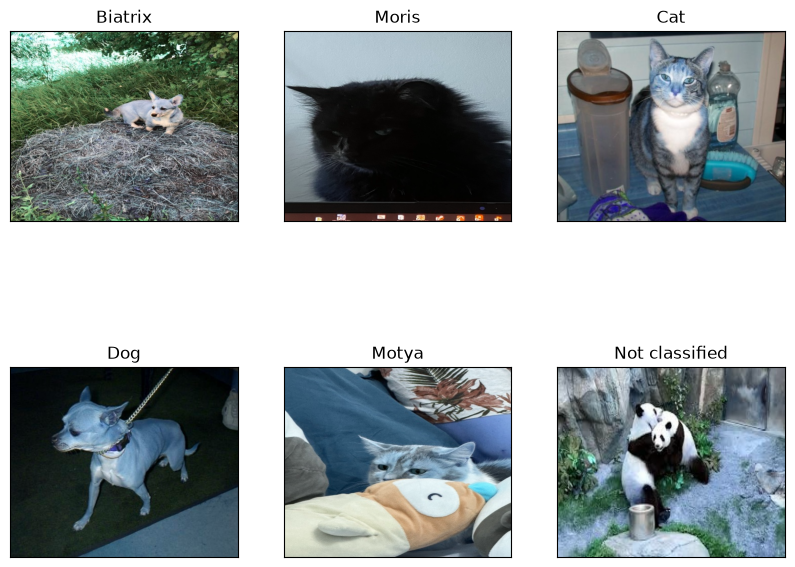

In [5]:
fig, ax = plt.subplots(2, 3,  figsize=(10, 8))
ax[0, 0].imshow(show("Biatrix")) 
ax[0,0].set_title("Biatrix")
ax[0,0].set_xticks([])
ax[0,0].set_yticks([])
ax[0, 1].imshow(show("Moris")) 
ax[0,1].set_title("Moris")
ax[0,1].set_xticks([])
ax[0,1].set_yticks([])
ax[0,2].imshow(show("Cat"))
ax[0,2].set_title("Cat")
ax[0,2].set_xticks([])
ax[0,2].set_yticks([])
ax[1, 0].imshow(show("Dog"))
ax[1,0].set_title("Dog")
ax[1,0].set_xticks([])
ax[1,0].set_yticks([])
ax[1, 1].imshow(show("Motya")) 
ax[1,1].set_title("Motya")
ax[1,1].set_xticks([])
ax[1,1].set_yticks([])
ax[1, 2].imshow(show())
ax[1,2].set_title("Not classified")
ax[1,2].set_xticks([])
ax[1,2].set_yticks([])

## Shape Check

In [47]:
show().shape

(375, 450, 3)

In [51]:
c = 0
for i in train_csv["image_id"]:
    img = cv2.imread(f"{TRAIN_DATA_PATH}/{i}.jpg")
    if img.shape != (375, 450, 3):
        c += 1
        print(c)
print(f"Wrong res:{c}")        


Wrong res:0


## Brightness

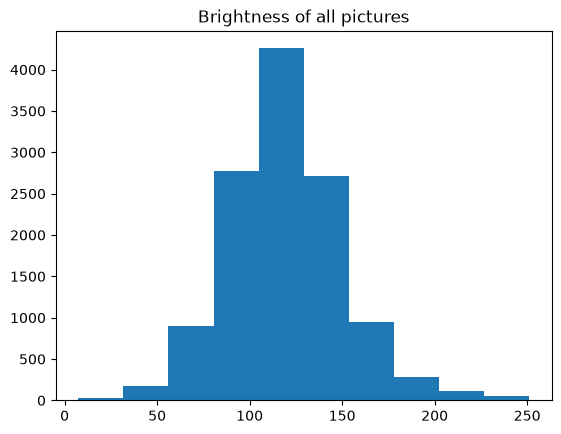

In [ ]:

def brightness(image_id, img_dir="data/train"):
    img = cv2.imread(f"{img_dir}/{image_id}.jpg", cv2.IMREAD_GRAYSCALE)
    if img is None:
        return np.nan
    return img.mean()

train_csv["Brightness"] = train_csv["image_id"].apply(brightness)
train_csv.sort_values(by = "Brightness")
plt.hist(train_csv["Brightness"])
plt.title("Brightness of all pictures")
plt.show()

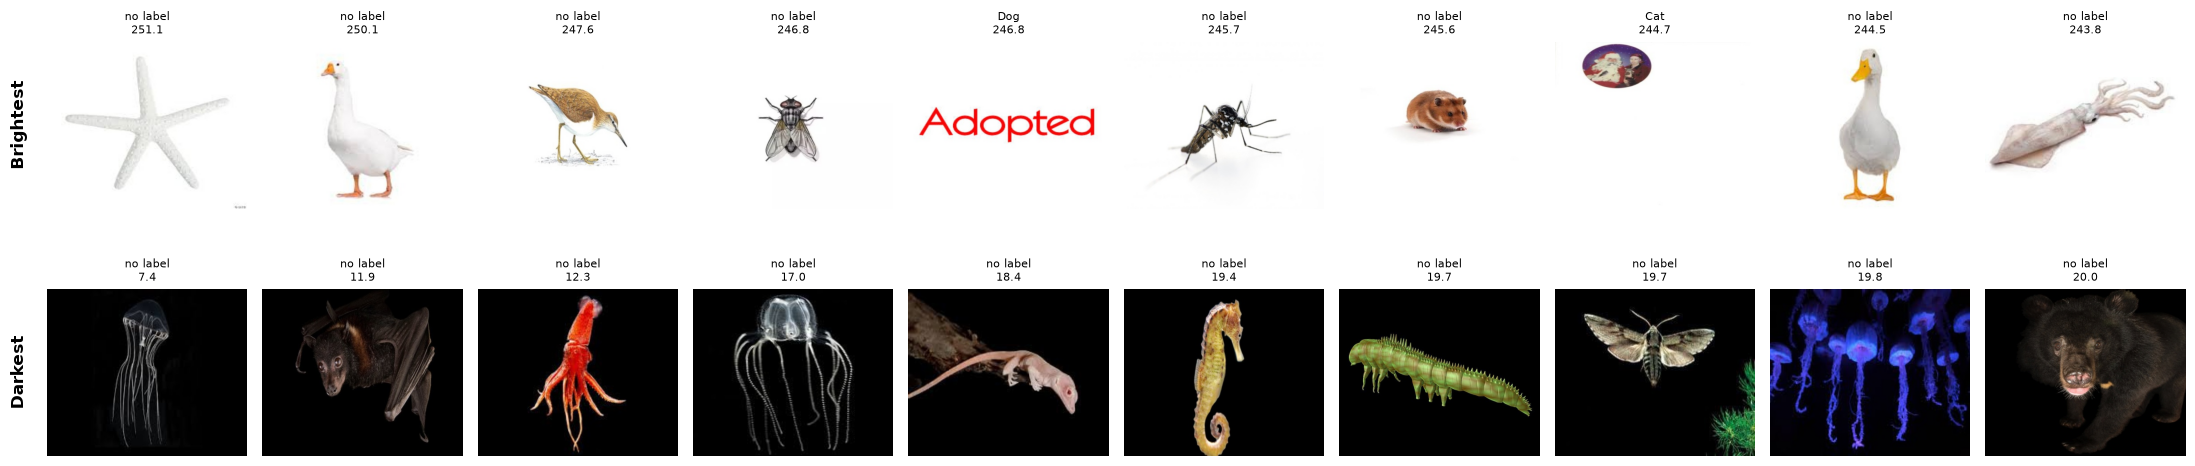

In [44]:
import matplotlib.pyplot as plt
from PIL import Image

def show_extremes(df, img_dir, label_cols, n=10, brightness_col="Brightness"):
    df = df.dropna(subset=[brightness_col])
    darkest   = df.nsmallest(n, brightness_col)
    brightest = df.nlargest(n, brightness_col)

    def get_label(row):
        names = [c for c in label_cols if row[c] > 0.5]
        return "/".join(names) if names else "no label"

    fig, axes = plt.subplots(2, n, figsize=(2.2 * n, 5.5))
    rows = [("Brightest", brightest), ("Darkest", darkest)]

    for r, (title, subset) in enumerate(rows):
        for c in range(n):
            ax = axes[r, c]
            ax.axis("off")
            if c >= len(subset):
                continue
            row = subset.iloc[c]
            img = Image.open(f"{img_dir}/{row['image_id']}.jpg").convert("RGB")
            ax.imshow(img)
            ax.set_title(f"{get_label(row)}\n{row[brightness_col]:.1f}", fontsize=8)
        # row title on the left-most axis
        axes[r, 0].text(-0.1, 0.5, title, transform=axes[r, 0].transAxes,
                        rotation=90, va="center", ha="right",
                        fontsize=12, fontweight="bold")

    plt.tight_layout()
    plt.show()

show_extremes(train_csv, TRAIN_DATA_PATH, label_cols)

## Labels distribution

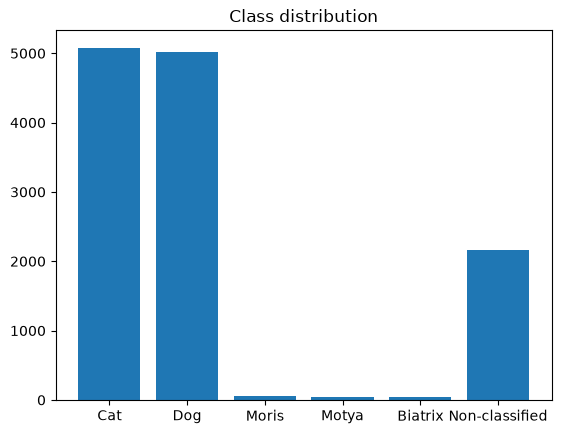

In [81]:
numbers = train_csv.iloc[:, 1:-1].sum(axis = 0)
numbers["Non-classified"] = len(train_csv.loc[np.sum(train_csv.iloc[:,1:-1], axis = 1)== 0])
plt.bar(numbers.index, numbers)
plt.title("Class distribution")
plt.show()

# Augmentations


In [ ]:
import albumentations as A
from PIL import Image
from torchvision.transforms.functional import to_pil_image
pipeline = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.07, p=0.5),         # 50% chance to flip horizontally
    A.RandomBrightnessContrast(p=0.7),  # 70% chance to adjust brightness/contrast
    A.GaussianBlur(blur_limit=3, p=0.3),
    A.CLAHE(),
    A.ImageCompression(compression_type="jpeg", quality_range=(10,40)),
    A.ElasticTransform(0.2),
    A.Affine(scale=(0.8, 1.2),
             rotate=(-30, 30))   
       
])
biatrix_ids = train_csv[train_csv["Biatrix"] == 1]["image_id"]
moris_ids = train_csv[train_csv["Moris"] == 1]["image_id"]
motya_ids = train_csv[train_csv["Motya"] == 1]["image_id"]


def augment_ids(df, ids, src_dir, out_dir, n, transform):
    if isinstance(df, pd.Series):            # tolerate swapped argument order
        df, ids = ids, df

    os.makedirs(out_dir, exist_ok=True)
    sub = os.path.basename(os.path.normpath(out_dir))
    lookup = df.set_index("image_id")
    new_rows = []

    for image_id in pd.Series(ids).unique():
        img = np.array(Image.open(f"{src_dir}/{image_id}.jpg").convert("RGB"))  # HxWx3 uint8
        base = lookup.loc[image_id]
        for i in range(n):
            out = transform(image=img)["image"]          # albumentations: dict in, dict out
            if hasattr(out, "detach"):                   # ToTensorV2 was used -> CHW tensor
                out = out.permute(1, 2, 0).cpu().numpy()
            out = np.clip(out, 0, 255).astype(np.uint8) if out.dtype != np.uint8 else out

            new_name = f"{image_id}_{i}_aug"
            Image.fromarray(out).save(f"{out_dir}/{new_name}.jpg", quality=95)

            row = base.copy()
            row["image_id"] = f"{sub}/{new_name}"
            new_rows.append(row)

    return pd.DataFrame(new_rows).reset_index(drop=True)

new_biatrix = augment_ids(train_csv, biatrix_ids, TRAIN_DATA_PATH,
                          TRAIN_DATA_PATH + "/aug/biatrix", 8, pipeline)
new_motya = augment_ids(train_csv, motya_ids, TRAIN_DATA_PATH,
                          TRAIN_DATA_PATH + "/aug/motya", 8, pipeline)
new_moris =  augment_ids(train_csv, moris_ids, TRAIN_DATA_PATH,
                          TRAIN_DATA_PATH + "/aug/moris", 8, pipeline)

Function is used to generate new data for low amount classes.
During Inference and CrossVal put outputdir into same datafolder as all images.
During Cross Validation to avoid data leakage, compute new `biatrix_ids = fold_csv[fold_csv["Biatrix"] == 1]["image_id"]
moris_ids = fold_csv[fold_csv["Moris"] == 1]["image_id"]
motya_ids = fold_csv[told_csv["Motya"] == 1]["image_id"]` for each train fold, and consequently append fold_csv with dataframe produced by `augment_ids function`